Character : Frequency : Huffman Code
    't'      :     1     : 01010
    'h'      :     2     : 0100
    'i'      :     3     : 1001
    's'      :     2     : 0010
    ' '      :     6     : 101
    'a'      :     3     : 1111
    'n'      :     4     : 000
    'e'      :     3     : 1110
    'x'      :     1     : 01110
    'm'      :     2     : 0011
    'p'      :     1     : 10000
    'l'      :     1     : 01101
    'f'      :     3     : 1101
    'o'      :     2     : 11001
    'r'      :     1     : 01100
    'u'      :     1     : 11000
    'c'      :     1     : 01111
    'd'      :     1     : 01011
    'g'      :     1     : 10001

Unique Characters : Time (seconds) : Peak Memory (KB)
  2 : 0.00006172 : 0.9219
  3 : 0.00006387 : 1.2715
  4 : 0.00006004 : 1.3164
  5 : 0.00012130 : 1.8164
  6 : 0.00011910 : 2.3838
  7 : 0.00015701 : 2.5996
  8 : 0.00006645 : 2.8154
  9 : 0.00006741 : 3.1377
 10 : 0.00008112 : 3.3857
 11 : 0.00007544 : 4.2432
 12 : 0.00007784 : 4.4473
 13 : 

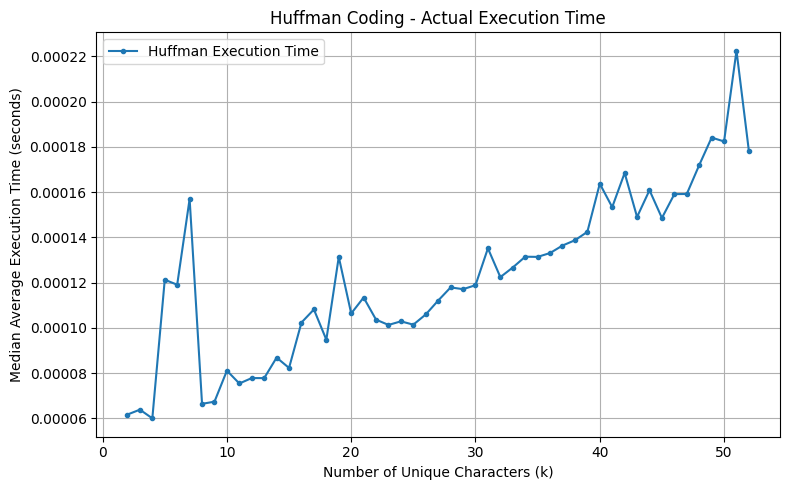

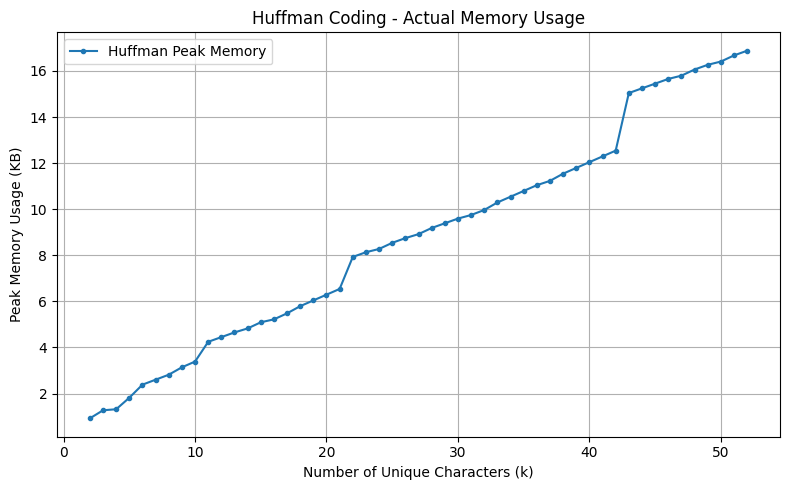

In [ ]:

import heapq
import matplotlib.pyplot as plt
from collections import Counter
from time import perf_counter
import tracemalloc
import statistics
import string


class Node:
    def __init__(self, char=None, freq=0, left=None, right=None):
        self.char = char
        self.freq = freq
        self.left = left
        self.right = right

    def __lt__(self, other):
        return self.freq < other.freq


def huffman(text):
    frequencies = Counter(text)

    if not frequencies:
        return {}

    heap = [Node(char, freq) for char, freq in frequencies.items()]
    heapq.heapify(heap)

    if len(heap) == 1:
        return {heap[0].char: "0"}

    # Build Huffman Tree
    while len(heap) > 1:
        left = heapq.heappop(heap)
        right = heapq.heappop(heap)

        parent = Node(
            freq=left.freq + right.freq,
            left=left,
            right=right
        )

        heapq.heappush(heap, parent)

    # Generate Huffman Codes
    codes = {}

    def generate(node, code=""):
        if node.char is not None:
            codes[node.char] = code
        else:
            generate(node.left, code + "0")
            generate(node.right, code + "1")

    generate(heap[0])
    return codes


# Example input
text = "this is an example for huffman encoding"
frequencies = Counter(text)
codes = huffman(text)

print("Character : Frequency : Huffman Code")
for char, freq in frequencies.items():
    print(f"{repr(char):^12} : {freq:^9} : {codes[char]}")


# Measure actual execution time
def measure_time(function, text, repeats=50, batches=3):
    times = []

    for _ in range(batches):
        start = perf_counter()

        for _ in range(repeats):
            function(text)

        end = perf_counter()
        times.append((end - start) / repeats)

    return statistics.median(times)


# Measure actual peak memory in KB
def measure_memory(function, text, repeats=3):
    memory_values = []

    for _ in range(repeats):
        tracemalloc.start()

        try:
            function(text)
            current, peak = tracemalloc.get_traced_memory()
        finally:
            tracemalloc.stop()

        memory_values.append(peak / 1024)

    return statistics.median(memory_values)


# Generate test strings with different numbers of unique characters
alphabet = string.ascii_letters
x = list(range(2, len(alphabet) + 1))

execution_times = []
memory_usage = []

for k in x:
    # Keep total string length fixed at 1000
    test_text = "".join(alphabet[i % k] for i in range(1000))

    execution_times.append(
        measure_time(huffman, test_text)
    )

    memory_usage.append(
        measure_memory(huffman, test_text)
    )


# Display measured results
print("\nUnique Characters : Time (seconds) : Peak Memory (KB)")

for k, t, m in zip(x, execution_times, memory_usage):
    print(f"{k:3d} : {t:.8f} : {m:.4f}")


# Graph 1: Actual execution time
plt.figure(figsize=(8, 5))
plt.plot(x, execution_times, marker='o', markersize=3,
         label="Huffman Execution Time")

plt.xlabel("Number of Unique Characters (k)")
plt.ylabel("Median Average Execution Time (seconds)")
plt.title("Huffman Coding - Actual Execution Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Graph 2: Actual peak memory usage
plt.figure(figsize=(8, 5))
plt.plot(x, memory_usage, marker='o', markersize=3,
         label="Huffman Peak Memory")

plt.xlabel("Number of Unique Characters (k)")
plt.ylabel("Peak Memory Usage (KB)")
plt.title("Huffman Coding - Actual Memory Usage")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
